## Calculus and vector fields

`integral` refines its subintervals until its error estimate is small enough, so it handles infinite limits and sharp peaks; `trapz` integrates sampled data. Here $\int_0^\infty e^{-x^2}\,dx = \sqrt{\pi}/2$.

In [ ]:
fprintf('integral %.15f, exact %.15f\n', integral(@(x) exp(-x.^2), 0, Inf), sqrt(pi)/2)
peak = integral(@(x) 1 ./ ((x - 0.3).^2 + 0.001), 0, 1)
xs = linspace(0, pi, 101);
by_trapz = trapz(xs, sin(xs))

integral 0.886226925452758, exact 0.886226925452758



peak =

   94.5972


by_trapz =

    1.9998



`cumtrapz` gives the integral up to each point, and `gradient` differentiates sampled values by central differences.

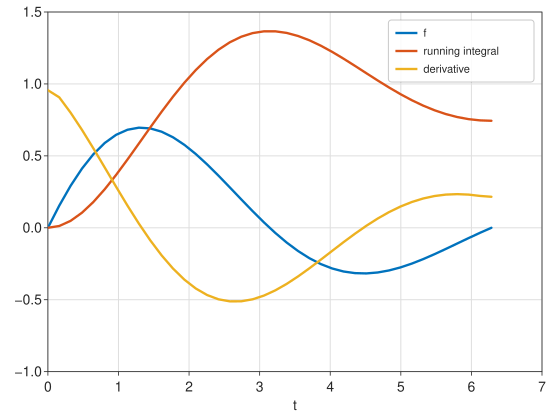

In [ ]:
figure
t = linspace(0, 2*pi, 40);
f = sin(t) .* exp(-t/4);
plot(t, f, t, cumtrapz(t, f), t, gradient(f, t(2) - t(1)), 'LineWidth', 1.2)
legend('f', 'running integral', 'derivative'), xlabel('t'), grid on

`fzero` finds a root in a bracket; `fminsearch` minimizes without derivatives (Nelder-Mead), here on Rosenbrock's valley, whose minimum is at `(1, 1)`.

In [ ]:
root = fzero(@(x) cos(x) - x, [0 1])
[vmin, fmin] = fminsearch(@(v) 100*(v(2) - v(1)^2)^2 + (1 - v(1))^2, [-1.2, 1])


root =

    0.7391




vmin =

    1.0000    1.0000


fmin =

   8.1777e-10



On a grid, `gradient` gives the partial derivatives of a field, and from them the divergence `du/dx + dv/dy` and the curl `dv/dx - du/dy`. The field `(-y, x)` is a pure rotation: divergence 0, curl 2. `4*del2` is the Laplacian: 4 for `x^2 + y^2`.

In [ ]:
[gx, gy] = meshgrid(linspace(-2, 2, 9));  h = gx(1, 2) - gx(1, 1);
u = -gy;  v = gx;
[ux, uy] = gradient(u, h);  [vx, vy] = gradient(v, h);
fprintf('divergence %g, curl %g\n', max(abs(ux(:) + vy(:))), mean(vx(:) - uy(:)))
lap = 4 * del2(gx.^2 + gy.^2, h);
fprintf('Laplacian between %.6f and %.6f\n', min(lap(:)), max(lap(:)))

divergence 0, curl 2
Laplacian between 4.000000 and 4.000000


*Thanks to MatRust-Studio (MIT license), whose examples suggested these topics; the code here is Sagebrush's own.*